# 03. Análisis y modelos del TFM

En este notebook buscamos responder a tres preguntas:

1. ¿Podemos predecir si una acción subirá al día siguiente utilizando datos de mercado?
2. ¿Existen patrones de comportamiento que se repiten, especialmente las subidas fuertes en la apertura seguidas de caídas durante el día?
3. ¿La información de las noticias analizada por el LLM ayuda a mejorar las predicciones?

Primero exploramos los datos y después entrenamos y comparamos diferentes modelos de Machine Learning. Para el modelo general, utilizamos 2021–2023 como entrenamiento, 2024 como validación y 2025 como prueba. En el análisis de los gaps, ampliamos progresivamente el entrenamiento y utilizamos 2026 como comprobación posterior.

## Guía del notebook

Cada sección indica qué pregunta responde, qué tablas y figuras produce y en qué apartado de la memoria aparecen:

- **1 y 2 (datos y EDA):** muestra general, capitalización y correlaciones. Memoria, apartado 5.1.
- **3 (modelo general):** si los datos de mercado predicen la subida de la sesión siguiente. Validación en 2024 y prueba en 2025. Memoria, apartado 5.2.1.
- **4 (cinco patrones):** frecuencia de cada patrón frente a una sesión cualquiera, por periodos. Memoria, apartado 5.2.2.
- **5 y 6 (modelo de gaps):** si los datos de mercado permiten anticipar qué gaps acaban en caída. Memoria, apartado 5.2.3.
- **7 (LLM):** distribución de la solidez asignada y su relación con la caída. Memoria, apartado 5.2.4.
- **8 (comparación principal):** AUC con y sin el LLM sobre los mismos gaps. Memoria, apartado 5.2.5.
- **9 (conclusiones):** respuesta a las preguntas de la memoria con los resultados de las secciones anteriores.

## 1. Cargar los datos

En este notebook analizamos los datos preparados anteriormente para comprobar si existen patrones de comportamiento en las acciones de baja capitalización y si podemos predecirlos mediante modelos de Machine Learning.

Primero estudiamos las características de los datos mediante gráficos y estadísticas descriptivas. Después comparamos diferentes modelos predictivos, analizamos los patrones seleccionados y, finalmente, comprobamos si añadir la información obtenida mediante el LLM mejora los resultados.

Para ello, cargamos la muestra general de 2021–2025, las sesiones utilizadas para estudiar los patrones y los eventos de gaps, incluyendo los datos de 2026.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, roc_curve, confusion_matrix

# Carpetas del proyecto
DATOS = Path("data")
RESULTADOS = Path("resultados")
RESULTADOS.mkdir(exist_ok=True)

# Cargamos los datos preparados en los notebooks anteriores
muestra = pd.read_parquet(DATOS / "muestra_smallcaps.parquet")
sesiones = pd.read_parquet(DATOS / "sesiones_apertura.parquet")
sesiones_2026 = pd.read_parquet(DATOS / "sesiones_apertura_2026.parquet")
eventos = pd.read_csv(DATOS / "eventos_gap40.csv", parse_dates=["fecha"])

# Preparamos las fechas
for df in [muestra, sesiones, sesiones_2026, eventos]:
    df["fecha"] = pd.to_datetime(df["fecha"])
    df["anio"] = df["fecha"].dt.year

# Comprobamos los datos disponibles
print("Muestra general:", len(muestra), "sesiones")
print("Empresas analizadas:", muestra["symbol"].nunique())
print("Eventos con gap >= 40 %:", len(eventos))

Muestra general: 1248847 sesiones
Empresas analizadas: 2014
Eventos con gap >= 40 %: 1818


In [2]:
# Funciones auxiliares
def intervalo_auc(y, prob, fechas, repeticiones=500):
    """Intervalo del 95 % del AUC. Se remuestrean días completos porque las acciones de un mismo día no son independientes."""
    y = np.asarray(y)
    prob = np.asarray(prob)
    dias = list(pd.Series(np.arange(len(y))).groupby(np.asarray(fechas)).indices.values())
    azar = np.random.default_rng(42)
    aucs = []
    for _ in range(repeticiones):
        idx = np.concatenate([dias[i] for i in azar.integers(0, len(dias), len(dias))])
        if y[idx].min() != y[idx].max():
            aucs.append(roc_auc_score(y[idx], prob[idx]))
    return {"AUC IC bajo": np.percentile(aucs, 2.5), "AUC IC alto": np.percentile(aucs, 97.5)}


## 2. Exploración de los datos (EDA)

Antes de entrenar los modelos, analizamos las características de los datos para conocer mejor la muestra utilizada. Revisamos cuántas empresas y sesiones tenemos por año, su capitalización bursátil y el porcentaje de sesiones en las que el precio sube al día siguiente.

Este análisis permite comprobar cómo se distribuyen los datos y detectar posibles diferencias entre los años estudiados.

,Empresas,Sesiones,Capitalizacion,Subidas
anio,,,,
2021,861,144538,120.74,46.39
2022,1214,218771,100.95,45.13
2023,1374,267860,92.25,46.03
2024,1496,292587,83.82,45.38
2025,1700,325091,78.99,45.25


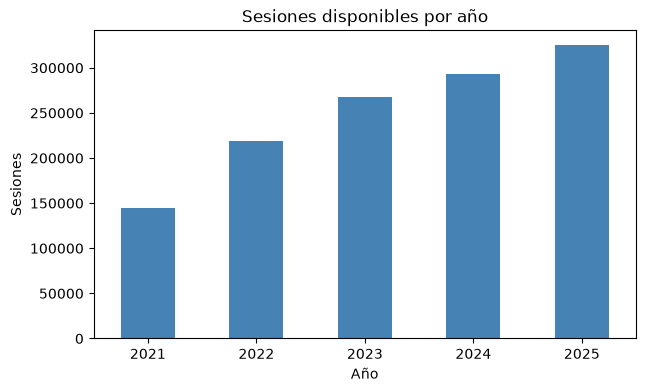

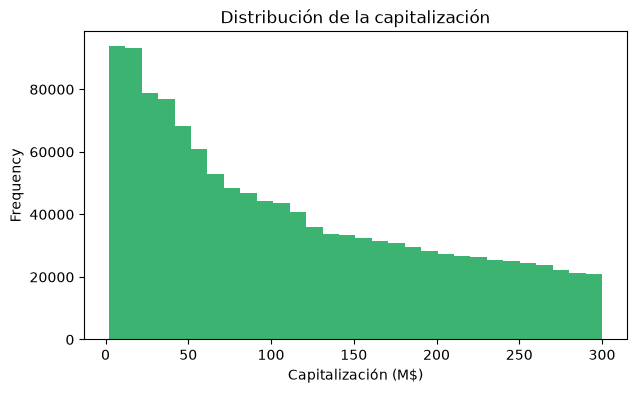

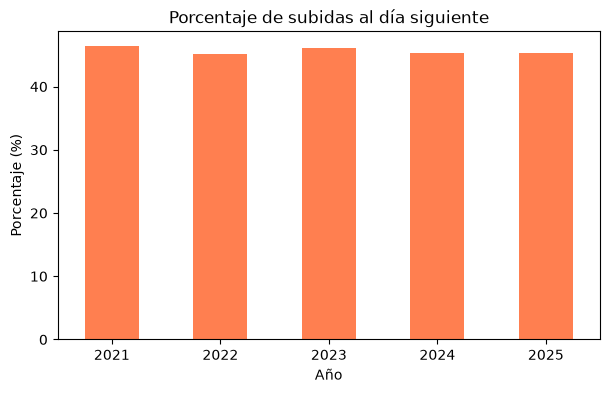

In [3]:
# Resumen de los datos por año
resumen = muestra.groupby("anio").agg(
    Empresas=("symbol", "nunique"),
    Sesiones=("symbol", "size"),
    Capitalizacion=("capitalizacion", "median"),
    Subidas=("sube", "mean")
)

resumen["Capitalizacion"] /= 1e6
resumen["Subidas"] *= 100

display(resumen.round(2))


# Sesiones por año
resumen["Sesiones"].plot.bar(
    color="steelblue",
    title="Sesiones disponibles por año",
    figsize=(7, 4)
)
plt.xlabel("Año")
plt.ylabel("Sesiones")
plt.xticks(rotation=0)
plt.show()


# Distribución de la capitalización
(muestra["capitalizacion"] / 1e6).plot.hist(
    bins=30,
    color="mediumseagreen",
    title="Distribución de la capitalización",
    figsize=(7, 4)
)
plt.xlabel("Capitalización (M$)")
plt.show()


# Porcentaje de subidas
resumen["Subidas"].plot.bar(
    color="coral",
    title="Porcentaje de subidas al día siguiente",
    figsize=(7, 4)
)
plt.xlabel("Año")
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=0)
plt.show()

In [4]:
%matplotlib inline
import os
CARPETA_FIG = RESULTADOS / "figuras_memoria"
os.makedirs(CARPETA_FIG, exist_ok=True)

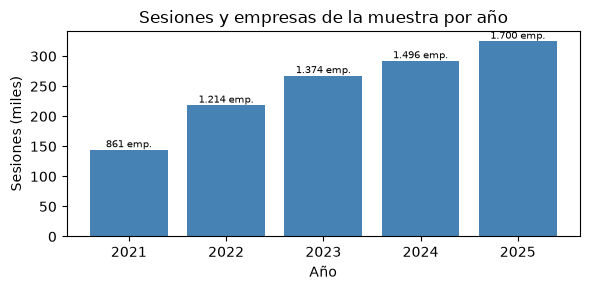

In [5]:
# Figura 5.1: sesiones y empresas de la muestra por año
res_anio = muestra.groupby("anio").agg(empresas=("symbol", "nunique"), sesiones=("symbol", "size"))

plt.figure(figsize=(6, 3))
plt.bar(res_anio.index.astype(str), res_anio["sesiones"] / 1000, color="steelblue")
for pos, (n_sesiones, n_empresas) in enumerate(zip(res_anio["sesiones"], res_anio["empresas"])):
    plt.text(pos, n_sesiones / 1000 + 4, f"{n_empresas:,} emp.".replace(",", "."), ha="center", fontsize=7)
plt.xlabel("Año")
plt.ylabel("Sesiones (miles)")
plt.title("Sesiones y empresas de la muestra por año")
plt.tight_layout()
plt.savefig(CARPETA_FIG / "figura_5_1.png", dpi=150)
plt.show()

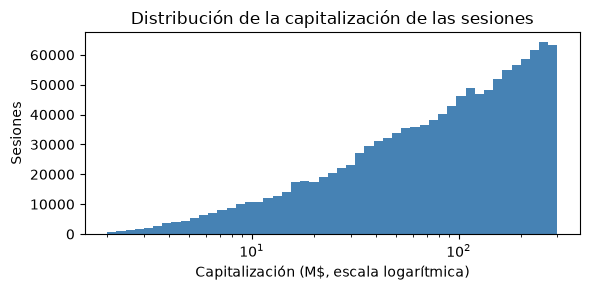

In [6]:
# Figura 5.2: distribución de la capitalización de las sesiones
plt.figure(figsize=(6, 3))
plt.hist(muestra["capitalizacion"] / 1e6, bins=np.logspace(np.log10(2), np.log10(300), 50), color="steelblue")
plt.xscale("log")
plt.xlabel("Capitalización (M$, escala logarítmica)")
plt.ylabel("Sesiones")
plt.title("Distribución de la capitalización de las sesiones")
plt.tight_layout()
plt.savefig(CARPETA_FIG / "figura_5_2.png", dpi=150)
plt.show()

In [7]:
# Variables del modelo general (21 variables de mercado conocidas al cierre de cada sesión)
VARIABLES = [
    "rent_1d", "gap", "rent_intradia", "rango", "pos_cierre", "dist_vwap",
    "rent_5d", "rent_10d", "rent_20d", "volat_5d", "volat_10d", "volat_20d",
    "dist_max_20d", "vol_rel_1d", "vol_rel_5d", "vol_rel_20d", "ops_rel_20d",
    "log_volumen_dolares", "rotacion", "log_capitalizacion", "log_precio"
]

## 3. ¿Podemos predecir la subida del día siguiente?

En este apartado comprobamos si los datos de mercado permiten predecir si una acción subirá o bajará en la siguiente sesión.

Para ello, comparamos tres modelos de Machine Learning: regresión logística, Random Forest y Gradient Boosting. Los tres utilizan las mismas 21 variables y se entrenan con datos de 2021 a 2023.
Utilizamos 2024 para comparar sus resultados y seleccionar el modelo con mejor AUC. Reservamos 2025 para comprobar posteriormente cómo funciona con datos que no se han utilizado para entrenar ni seleccionar el modelo.

Antes del entrenamiento, limitamos los valores extremos utilizando los datos de entrenamiento y estandarizamos las variables para la regresión logística. Evaluamos los resultados mediante AUC, F1 y exactitud.

In [8]:
# Separamos los datos por periodos
ent = muestra[muestra["anio"].between(2021, 2023)].dropna(subset=VARIABLES + ["sube"])
val = muestra[muestra["anio"] == 2024].dropna(subset=VARIABLES + ["sube"])
pru = muestra[muestra["anio"] == 2025].dropna(subset=VARIABLES + ["sube"])

# Limitamos los valores extremos según el entrenamiento
bajo = ent[VARIABLES].quantile(0.01)
alto = ent[VARIABLES].quantile(0.99)

X_ent = ent[VARIABLES].clip(bajo, alto, axis=1)
X_val = val[VARIABLES].clip(bajo, alto, axis=1)

# Modelos que vamos a comparar
modelos = {
    "Regresión logística": make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1.0, max_iter=1000)
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=500,
        max_features="sqrt",
        max_samples=0.25,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=31,
        min_samples_leaf=1000,
        l2_regularization=1,
        early_stopping=False,
        random_state=42
    )
}

# Calculamos las métricas de evaluación
def metricas(y, prob):
    pred = prob >= 0.5

    return {
        "AUC": roc_auc_score(y, prob),
        "F1": f1_score(y, pred),
        "Exactitud": accuracy_score(y, pred),
        "Referencia": max(y.mean(), 1 - y.mean())
    }


# Entrenamos y evaluamos cada modelo
resultados = []
probabilidades_2024 = {}

for nombre, modelo in modelos.items():
    modelo.fit(X_ent, ent["sube"])

    prob = modelo.predict_proba(X_val)[:, 1]
    probabilidades_2024[nombre] = prob

    resultados.append({
        "Modelo": nombre,
        **metricas(val["sube"], prob)
    })

validacion = pd.DataFrame(resultados).sort_values(
    "AUC", ascending=False
)

display(validacion.round(3))

,Modelo,AUC,F1,Exactitud,Referencia
2,Gradient Boosting,0.568,0.329,0.562,0.546
1,Random Forest,0.567,0.262,0.561,0.546
0,Regresión logística,0.558,0.321,0.556,0.546


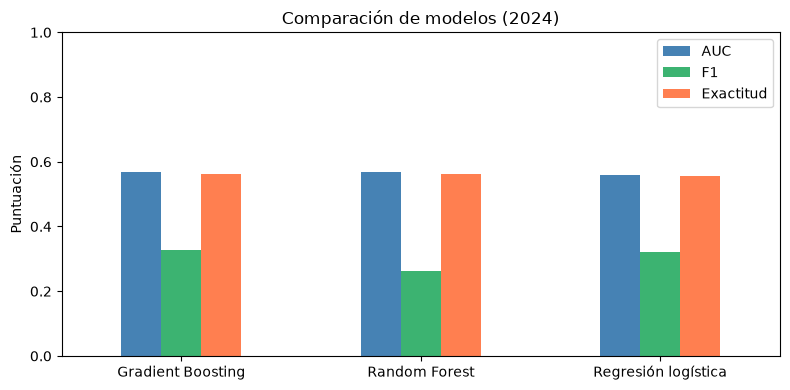

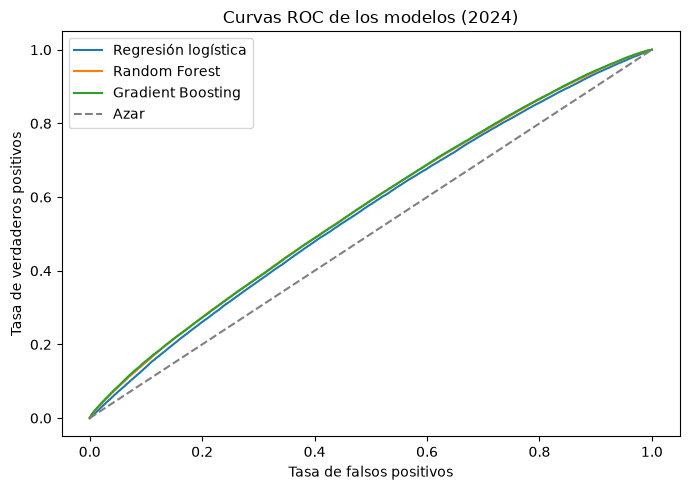

In [9]:
# Comparación de métricas
validacion.set_index("Modelo")[["AUC", "F1", "Exactitud"]].plot.bar(
    figsize=(8, 4),
    color=["steelblue", "mediumseagreen", "coral"],
    title="Comparación de modelos (2024)"
)

plt.ylabel("Puntuación")
plt.xlabel("")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


# Curvas ROC
plt.figure(figsize=(7, 5))

for nombre, prob in probabilidades_2024.items():
    fpr, tpr, _ = roc_curve(val["sube"], prob)
    plt.plot(fpr, tpr, label=nombre)

plt.plot([0, 1], [0, 1], "--", color="gray", label="Azar")

plt.title("Curvas ROC de los modelos (2024)")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.tight_layout()
plt.show()

### 3.1 Comprobar el modelo elegido en 2025

Una vez comparados los modelos con los datos de 2024, seleccionamos el que ha obtenido el mejor AUC. Volvemos a entrenarlo utilizando todos los datos disponibles entre 2021 y 2024 y evaluamos sus resultados en 2025. De esta manera, comprobamos si mantiene su capacidad predictiva en un periodo que no se ha utilizado para entrenarlo ni seleccionarlo. También analizamos sus aciertos y errores mediante una matriz de confusión.

Modelo seleccionado: Gradient Boosting


,Modelo,AUC,F1,Exactitud,Referencia
0,Gradient Boosting,0.568,0.292,0.563,0.548


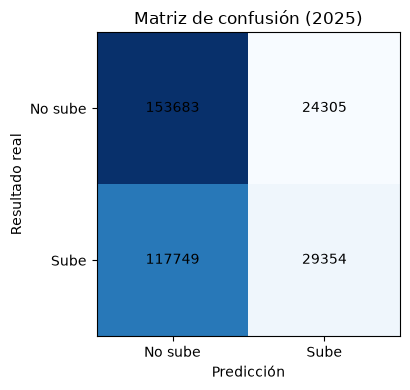

In [10]:
# Seleccionamos el modelo con mejor AUC en 2024
mejor = validacion.iloc[0]["Modelo"]

# Entrenamos de nuevo con los datos de 2021 a 2024
ent_final = pd.concat([ent, val])

bajo_final = ent_final[VARIABLES].quantile(0.01)
alto_final = ent_final[VARIABLES].quantile(0.99)

X_final = ent_final[VARIABLES].clip(bajo_final, alto_final, axis=1)
X_2025 = pru[VARIABLES].clip(bajo_final, alto_final, axis=1)

# Volvemos a entrenar el modelo seleccionado
modelo_final = modelos[mejor]
modelo_final.fit(X_final, ent_final["sube"])

# Evaluamos con los datos de 2025
prob_2025 = modelo_final.predict_proba(X_2025)[:, 1]

prueba_general = pd.DataFrame([{
    "Modelo": mejor,
    **metricas(pru["sube"], prob_2025)
}])

print("Modelo seleccionado:", mejor)
display(prueba_general.round(3))


# Matriz de confusión
matriz = confusion_matrix(pru["sube"], prob_2025 >= 0.5)

plt.figure(figsize=(5, 4))
plt.imshow(matriz, cmap="Blues")

plt.xticks([0, 1], ["No sube", "Sube"])
plt.yticks([0, 1], ["No sube", "Sube"])
plt.xlabel("Predicción")
plt.ylabel("Resultado real")
plt.title("Matriz de confusión (2025)")

for i in range(2):
    for j in range(2):
        plt.text(j, i, matriz[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

In [11]:
# Intervalos de confianza del AUC del modelo general (remuestreo de días completos, 200 repeticiones)
ic_validacion = {m: intervalo_auc(val["sube"], probabilidades_2024[m], val["fecha"], 200) for m in probabilidades_2024}
validacion["IC 95 % inferior"] = validacion["Modelo"].map(lambda m: ic_validacion[m]["AUC IC bajo"])
validacion["IC 95 % superior"] = validacion["Modelo"].map(lambda m: ic_validacion[m]["AUC IC alto"])
display(validacion.round(3))

ic_prueba = intervalo_auc(pru["sube"], prob_2025, pru["fecha"], 200)
prueba_general["IC 95 % inferior"] = ic_prueba["AUC IC bajo"]
prueba_general["IC 95 % superior"] = ic_prueba["AUC IC alto"]
display(prueba_general.round(3))
validacion.to_csv(RESULTADOS / "validacion_general.csv", index=False)
prueba_general.to_csv(RESULTADOS / "prueba_general.csv", index=False)


,Modelo,AUC,F1,Exactitud,Referencia,IC 95 % inferior,IC 95 % superior
2,Gradient Boosting,0.568,0.329,0.562,0.546,0.563,0.574
1,Random Forest,0.567,0.262,0.561,0.546,0.563,0.573
0,Regresión logística,0.558,0.321,0.556,0.546,0.553,0.563


,Modelo,AUC,F1,Exactitud,Referencia,IC 95 % inferior,IC 95 % superior
0,Gradient Boosting,0.568,0.292,0.563,0.548,0.562,0.573


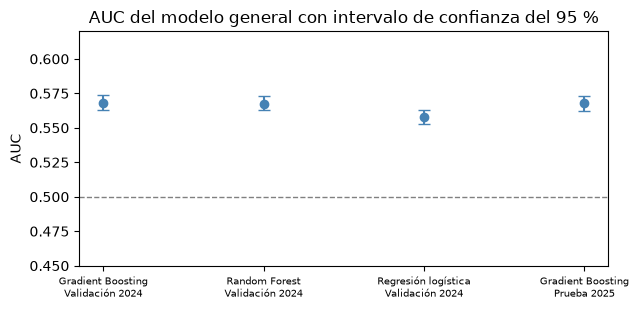

In [12]:
# Figura 5.4: AUC del modelo general con su intervalo de confianza
filas_g = pd.concat([validacion.assign(Periodo="Validación 2024"), prueba_general.assign(Periodo="Prueba 2025")])
x = np.arange(len(filas_g))
errores = np.vstack([filas_g["AUC"] - filas_g["IC 95 % inferior"], filas_g["IC 95 % superior"] - filas_g["AUC"]])

plt.figure(figsize=(6.5, 3.2))
plt.errorbar(x, filas_g["AUC"], yerr=errores, fmt="o", color="steelblue", capsize=4)
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.xticks(x, [f"{m}\n{p}" for m, p in zip(filas_g["Modelo"], filas_g["Periodo"])], fontsize=7)
plt.ylabel("AUC")
plt.ylim(0.45, 0.62)
plt.title("AUC del modelo general con intervalo de confianza del 95 %")
plt.tight_layout()
plt.savefig(CARPETA_FIG / "figura_5_4.png", dpi=150)
plt.show()

## 4. ¿Se repiten los cinco patrones?

En este apartado analizamos cinco patrones de comportamiento para comprobar con qué frecuencia aparecen y si se cumple el resultado esperado. Para cada patrón calculamos el número de casos y el porcentaje de veces que ocurre el comportamiento esperado. También comparamos ese porcentaje con el comportamiento habitual del mismo año, para comprobar si existe una diferencia relevante.

Utilizamos los datos de 2021 a 2025 para comparar los patrones y seleccionar uno para estudiarlo con mayor profundidad. Los resultados de 2026 se analizan posteriormente como una comprobación adicional.

In [13]:
# Definimos los cinco patrones y el resultado esperado
def patrones_de(df):
    return [
        ("Gap alcista ≥40 %", df["gap"] >= 0.40,
         df["rent_intradia"] < 0, "rent_intradia"),

        ("Gap bajista ≤-10 %", df["gap"] <= -0.10,
         df["rent_intradia"] > 0, "rent_intradia"),

        ("Subida diaria ≥20 %", df["rent_1d"] >= 0.20,
         df["variacion_siguiente"] < 0, "variacion_siguiente"),

        ("Caída diaria ≤-20 %", df["rent_1d"] <= -0.20,
         df["variacion_siguiente"] > 0, "variacion_siguiente"),

        ("Volumen ≥5 veces", df["vol_rel_20d"] >= np.log(5),
         df["variacion_siguiente"] > 0, "variacion_siguiente")
    ]


# Calculamos los resultados de cada patrón por año
filas = []

for anio, df in pd.concat([sesiones, sesiones_2026]).groupby("anio"):
    for nombre, condicion, resultado, columna in patrones_de(df):

        validas = df[columna].notna()
        casos = condicion & validas

        porcentaje = resultado[casos].mean() * 100
        habitual = resultado[validas].mean() * 100

        filas.append({
            "Año": anio,
            "Patrón": nombre,
            "Casos": casos.sum(),
            "% resultado": porcentaje,
            "% habitual": habitual,
            "Diferencia (pp)": porcentaje - habitual
        })

patrones = pd.DataFrame(filas)

# Comparación de 2021 a 2025
historico = patrones[patrones["Año"] <= 2025]

display(historico.round(1))


# Resumen de los cinco patrones
resumen_patrones = historico.groupby("Patrón").agg(
    Casos=("Casos", "sum"),
    Diferencia_minima=("Diferencia (pp)", "min")
)

print("Resumen de patrones (2021–2025):")
display(resumen_patrones.round(1))


# Comprobación posterior con 2026
print("Resultados de 2026:")
display(patrones[patrones["Año"] == 2026].round(1))

,Año,Patrón,Casos,% resultado,% habitual,Diferencia (pp)
0,2021,Gap alcista ≥40 %,107,75.7,51.1,24.6
1,2021,Gap bajista ≤-10 %,388,49.5,45.1,4.4
2,2021,Subida diaria ≥20 %,643,67.5,50.4,17.1
3,2021,Caída diaria ≤-20 %,177,40.1,46.2,-6.1
4,2021,Volumen ≥5 veces,3108,42.0,46.2,-4.2
5,2022,Gap alcista ≥40 %,98,72.4,51.0,21.4
6,2022,Gap bajista ≤-10 %,814,66.5,44.5,22.0
7,2022,Subida diaria ≥20 %,1086,56.4,51.1,5.2
8,2022,Caída diaria ≤-20 %,466,44.0,45.1,-1.1
9,2022,Volumen ≥5 veces,4343,43.5,45.1,-1.6


Resumen de patrones (2021–2025):


,Casos,Diferencia_minima
Patrón,,
Caída diaria ≤-20 %,4168,-6.1
Gap alcista ≥40 %,1307,16.0
Gap bajista ≤-10 %,6158,4.4
Subida diaria ≥20 %,9758,5.2
Volumen ≥5 veces,28826,-4.3


Resultados de 2026:


,Año,Patrón,Casos,% resultado,% habitual,Diferencia (pp)
25,2026,Gap alcista ≥40 %,511,70.3,50.7,19.5
26,2026,Gap bajista ≤-10 %,2436,56.4,44.4,12.0
27,2026,Subida diaria ≥20 %,2740,60.4,51.6,8.8
28,2026,Caída diaria ≤-20 %,1700,44.5,44.3,0.3
29,2026,Volumen ≥5 veces,7090,42.6,44.3,-1.6


In [14]:
# Comparación por periodos, como en la memoria: 2021–2023, 2024 y 2025 (2026 solo como comprobación)
todas = pd.concat([sesiones, sesiones_2026])
periodos = {"2021–2023": [2021, 2022, 2023], "2024": [2024], "2025": [2025], "2026": [2026]}

filas = []
for periodo, años in periodos.items():
    df_p = todas[todas["anio"].isin(años)]
    for nombre, condicion, resultado, columna in patrones_de(df_p):
        validas = df_p[columna].notna()
        casos = condicion & validas
        filas.append({
            "Periodo": periodo,
            "Patrón": nombre,
            "Casos": int(casos.sum()),
            "% resultado": resultado[casos].mean() * 100,
            "% sesión cualquiera": resultado[validas].mean() * 100
        })

por_periodo = pd.DataFrame(filas)
por_periodo["Diferencia (pp)"] = por_periodo["% resultado"] - por_periodo["% sesión cualquiera"]
display(por_periodo.round(1))

# Diferencia mínima entre los periodos 2021–2025: el patrón se considera estable si es positiva en todos ellos
resumen_patrones = por_periodo[por_periodo["Periodo"] != "2026"].groupby("Patrón").agg(
    Casos=("Casos", "sum"),
    Diferencia_minima=("Diferencia (pp)", "min")
)
print("Resumen de patrones (2021–2025, mínimo entre periodos):")
display(resumen_patrones.round(1))


,Periodo,Patrón,Casos,% resultado,% sesión cualquiera,Diferencia (pp)
0,2021–2023,Gap alcista ≥40 %,421,72.7,50.8,21.9
1,2021–2023,Gap bajista ≤-10 %,2376,61.3,44.7,16.6
2,2021–2023,Subida diaria ≥20 %,3594,59.4,50.5,9.0
3,2021–2023,Caída diaria ≤-20 %,1426,43.4,45.7,-2.3
4,2021–2023,Volumen ≥5 veces,13287,43.4,45.7,-2.3
5,2024,Gap alcista ≥40 %,369,67.2,51.2,16.0
6,2024,Gap bajista ≤-10 %,1668,57.7,44.1,13.6
7,2024,Subida diaria ≥20 %,2838,58.3,50.6,7.6
8,2024,Caída diaria ≤-20 %,1141,46.8,45.4,1.4
9,2024,Volumen ≥5 veces,7238,43.6,45.4,-1.8


Resumen de patrones (2021–2025, mínimo entre periodos):


,Casos,Diferencia_minima
Patrón,,
Caída diaria ≤-20 %,4168,-4.5
Gap alcista ≥40 %,1307,16.0
Gap bajista ≤-10 %,6158,9.2
Subida diaria ≥20 %,9758,7.6
Volumen ≥5 veces,28826,-4.3


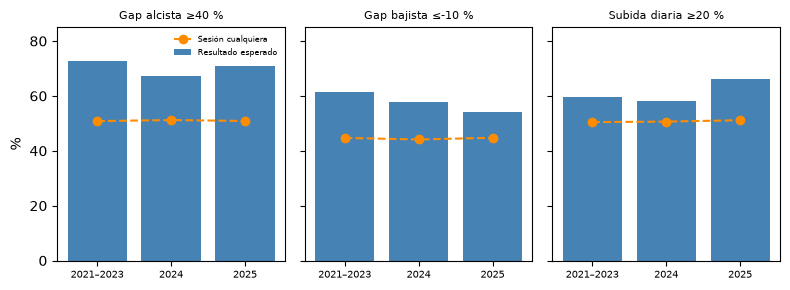

In [15]:
# Figura 5.5: resultado esperado de los tres patrones con mayor diferencia, frente a lo habitual, por periodo
patrones = ["Gap alcista ≥40 %", "Gap bajista ≤-10 %", "Subida diaria ≥20 %"]
fig, axes = plt.subplots(1, 3, figsize=(8, 3), sharey=True)
for ax, patron in zip(axes, patrones):
    d = por_periodo[(por_periodo["Patrón"] == patron) & (por_periodo["Periodo"] != "2026")]
    ax.bar(d["Periodo"], d["% resultado"], color="steelblue", label="Resultado esperado")
    ax.plot(d["Periodo"], d["% sesión cualquiera"], "o--", color="darkorange", label="Sesión cualquiera")
    ax.set_title(patron, fontsize=8)
    ax.tick_params(axis="x", labelsize=7)
axes[0].set_ylabel("%")
axes[0].set_ylim(0, 85)
axes[0].legend(fontsize=6, frameon=False)
plt.tight_layout()
plt.savefig(CARPETA_FIG / "figura_5_5.png", dpi=150)
plt.show()

## 5. Centrarnos en los gaps alcistas del 40 %

En este apartado nos centramos en las acciones que abren con una subida del 40 % o más respecto al cierre anterior. Consideramos que se produce un crap (crap = 1) cuando la acción termina la sesión por debajo de su precio de apertura.

Aunque este comportamiento se repita con frecuencia, eso no significa que podamos predecir qué acciones caerán. Para comprobarlo, entrenaremos modelos utilizando únicamente información disponible antes o en el momento de la apertura.

,Eventos,Porcentaje_caidas
anio,,
2021,107,75.7
2022,98,72.4
2023,216,71.3
2024,369,67.2
2025,517,71.0
2026,511,70.3


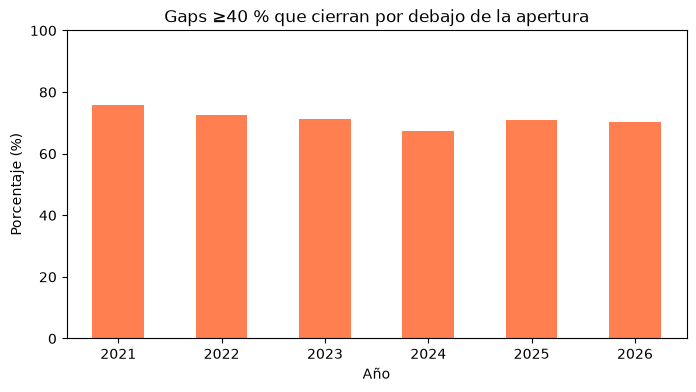

In [16]:
# Número de gaps y porcentaje que terminan con caída
tabla_gaps = eventos.groupby("anio").agg(
    Eventos=("crap", "size"),
    Porcentaje_caidas=("crap", "mean")
)

tabla_gaps["Porcentaje_caidas"] *= 100

display(tabla_gaps.round(1))


# Porcentaje de gaps que cierran por debajo de la apertura
tabla_gaps["Porcentaje_caidas"].plot.bar(
    figsize=(8, 4),
    color="coral",
    title="Gaps ≥40 % que cierran por debajo de la apertura"
)

plt.xlabel("Año")
plt.ylabel("Porcentaje (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

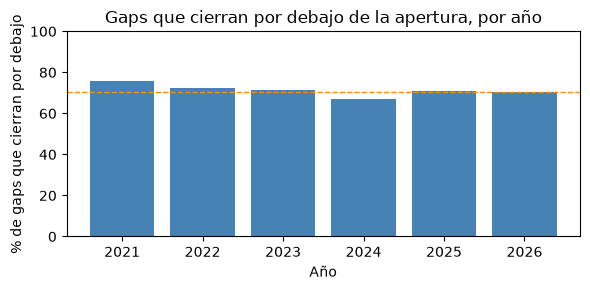

In [17]:
# Figura 5.3: porcentaje de gaps que cierran por debajo de la apertura, por año
pct_anio = eventos.groupby("anio")["crap"].mean() * 100

plt.figure(figsize=(6, 3))
plt.bar(pct_anio.index.astype(str), pct_anio.values, color="steelblue")
plt.axhline(100 * eventos["crap"].mean(), color="darkorange", linestyle="--", linewidth=1)
plt.xlabel("Año")
plt.ylabel("% de gaps que cierran por debajo")
plt.ylim(0, 100)
plt.title("Gaps que cierran por debajo de la apertura, por año")
plt.tight_layout()
plt.savefig(CARPETA_FIG / "figura_5_3.png", dpi=150)
plt.show()

## 6. Modelos para predecir el resultado de los gaps

En este apartado comprobamos si podemos predecir qué acciones cerrarán por debajo de su precio de apertura después de un gap alcista del 40 % o más.

Para ello, utilizamos el tamaño del gap y las variables de mercado disponibles antes o en el momento de la apertura. Comparamos regresión logística, Random Forest y Gradient Boosting.

El entrenamiento se amplía progresivamente: primero entrenamos con 2021–2023 y evaluamos en 2024; después incorporamos 2024 para evaluar en 2025 y, finalmente, utilizamos 2021–2025 para evaluar en 2026.

Los resultados de 2024 y 2025 tienen carácter exploratorio porque estos años también participaron en la selección del patrón. Reservamos 2026 como comprobación posterior.

In [18]:
# Variables disponibles en el momento de la apertura
VARIABLES_GAP = [
    "gap", "log_precio_apertura", "log_cap_previa", "rent_1d_previo",
    "rent_5d_previo", "rent_20d_previo", "volat_20d_previo",
    "dist_max_20d_previo", "pos_cierre_previo", "vol_rel_20d_previo",
    "ops_rel_20d_previo", "log_volumen_dolares_previo",
    "rotacion_previo", "gap_previo"
]

# Modelos utilizados
def modelos_gap():
    return {
        "Regresión logística": make_pipeline(
            StandardScaler(),
            LogisticRegression(C=0.5, max_iter=5000)
        ),

        "Random Forest": RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=20,
            random_state=42,
            n_jobs=-1
        ),

        "Gradient Boosting": HistGradientBoostingClassifier(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            min_samples_leaf=20,
            l2_regularization=1,
            random_state=42
        )
    }


# Evaluamos los modelos ampliando el entrenamiento cada año
def evaluar_gaps(datos, variables, tipo):
    resultados = []
    predicciones = []

    for anio in [2024, 2025, 2026]:
        ent_gap = datos[datos["anio"] < anio].dropna(subset=variables + ["crap"])
        pru_gap = datos[datos["anio"] == anio].dropna(subset=variables + ["crap"])

        if (len(ent_gap) < 30 or len(pru_gap) < 10 or
            ent_gap["crap"].nunique() < 2 or pru_gap["crap"].nunique() < 2):
            print("Datos insuficientes:", tipo, anio)
            continue

        for nombre, modelo in modelos_gap().items():
            modelo.fit(ent_gap[variables], ent_gap["crap"])
            prob = modelo.predict_proba(pru_gap[variables])[:, 1]

            resultados.append({
                "Tipo": tipo,
                "Año": anio,
                "Modelo": nombre,
                "Casos": len(pru_gap),
                **metricas(pru_gap["crap"], prob),
                **intervalo_auc(pru_gap["crap"], prob, pru_gap["fecha"])
            })

            predicciones.append(pd.DataFrame({
                "id_evento": pru_gap["id_evento"].values,
                "fecha": pru_gap["fecha"].values,
                "Año": anio,
                "Modelo": nombre,
                "Real": pru_gap["crap"].values,
                "Probabilidad": prob
            }))

    tabla = pd.DataFrame(resultados)
    preds = pd.concat(predicciones, ignore_index=True) if predicciones else pd.DataFrame()

    return tabla, preds


# Evaluamos los modelos con variables de mercado
mercado, pred_mercado = evaluar_gaps(
    eventos, VARIABLES_GAP, "Solo mercado"
)

display(mercado.round(3))

,Tipo,Año,Modelo,Casos,AUC,F1,Exactitud,Referencia,AUC IC bajo,AUC IC alto
0,Solo mercado,2024,Regresión logística,369,0.563,0.803,0.675,0.672,0.497,0.632
1,Solo mercado,2024,Random Forest,369,0.543,0.804,0.672,0.672,0.476,0.602
2,Solo mercado,2024,Gradient Boosting,369,0.504,0.784,0.667,0.672,0.431,0.560
3,Solo mercado,2025,Regresión logística,517,0.506,0.830,0.710,0.710,0.447,0.562
4,Solo mercado,2025,Random Forest,517,0.555,0.830,0.710,0.710,0.500,0.611
5,Solo mercado,2025,Gradient Boosting,517,0.564,0.798,0.681,0.710,0.509,0.620
6,Solo mercado,2026,Regresión logística,511,0.541,0.821,0.701,0.703,0.486,0.593
7,Solo mercado,2026,Random Forest,511,0.552,0.825,0.703,0.703,0.499,0.607
8,Solo mercado,2026,Gradient Boosting,511,0.535,0.798,0.673,0.703,0.482,0.586


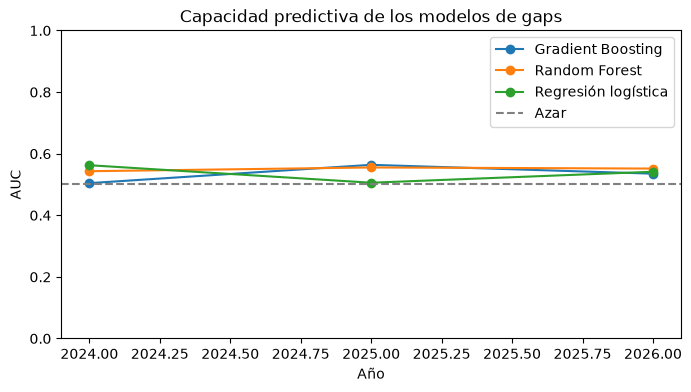

In [19]:
# Comparación del AUC de los tres modelos por año
if not mercado.empty:
    mercado.pivot(
        index="Año",
        columns="Modelo",
        values="AUC"
    ).plot(
        figsize=(8, 4),
        marker="o",
        title="Capacidad predictiva de los modelos de gaps"
    )

    plt.axhline(0.5, color="gray", linestyle="--", label="Azar")
    plt.xlabel("Año")
    plt.ylabel("AUC")
    plt.ylim(0, 1)
    plt.legend()
    plt.show()

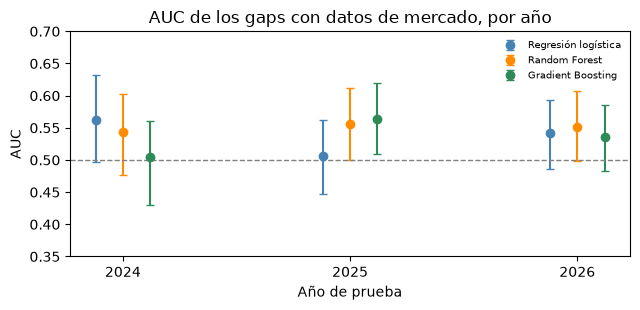

In [20]:
# Figura 5.6: AUC de los tres modelos de gaps con datos de mercado, en cada año de prueba
colores = {"Regresión logística": "steelblue", "Random Forest": "darkorange", "Gradient Boosting": "seagreen"}
plt.figure(figsize=(6.5, 3.2))
for desplazamiento, modelo in enumerate(colores):
    d = mercado[mercado["Modelo"] == modelo]
    plt.errorbar(
        d["Año"] + (desplazamiento - 1) * 0.12,
        d["AUC"],
        yerr=[d["AUC"] - d["AUC IC bajo"], d["AUC IC alto"] - d["AUC"]],
        fmt="o", color=colores[modelo], capsize=3, label=modelo
    )
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.xticks([2024, 2025, 2026])
plt.xlabel("Año de prueba")
plt.ylabel("AUC")
plt.ylim(0.35, 0.7)
plt.legend(fontsize=7, frameon=False)
plt.title("AUC de los gaps con datos de mercado, por año")
plt.tight_layout()
plt.savefig(CARPETA_FIG / "figura_5_6.png", dpi=150)
plt.show()

### Diseño cerrado del análisis de gaps

Especificación fijada antes de la comparación final; no se modifica tras ver los resultados de 2024–2026.

- **Objetivo:** `crap` = 1 si el cierre es inferior a la apertura (gap ≥ 40 %).
- **Variables de mercado:** las 14 de `VARIABLES_GAP`, conocidas en la apertura.
- **Contexto:** `solidez` (0–3) y `sin_documentos`, valorados por el prompt de `02_contexto_simplificado.ipynb`.
- **Modelos:** regresión logística, Random Forest y Gradient Boosting, con los parámetros de esta sección.
- **Entrenamiento:** creciente por años (2024 con 2021–2023; 2025 con 2021–2024; 2026 con 2021–2025).
- **Métrica principal:** AUC. Comparación pareada entre «Solo mercado» y «Mercado + LLM» sobre los mismos gaps, con intervalo del 95 % por remuestreo de días completos.
- **Hipótesis nula:** la diferencia de AUC (LLM − mercado) es 0.

**Limitaciones de diseño:** 2024–2026 ya se han consultado en versiones anteriores de este notebook, así que la prueba no es completamente independiente. Con unos 400–500 gaps por año, una mejora de AUC de 0,06 se detecta solo con alrededor del 60 % de probabilidad, y hace falta una mejora de unos 0,07 para tener el 80 %. Juntando 2024–2026 (unos 1.400 gaps), el umbral del 80 % baja a unos 0,045.


## 7. ¿Qué ha encontrado el LLM en las noticias?

En este apartado analizamos las valoraciones que ha realizado el LLM sobre las noticias y los comunicados disponibles antes de cada gap.

El modelo asigna una puntuación de 0 a 3 según la relevancia de la información encontrada. También distinguimos los casos sin documentos de aquellos en los que había información, pero no se identificó ningún catalizador claro.

Primero observamos cómo se distribuyen estas valoraciones y después comprobamos si están relacionadas con la probabilidad de que la acción cierre por debajo de su apertura.

In [21]:
# Cargamos las valoraciones del LLM
contexto = pd.read_csv(DATOS / "contexto_gap40.csv")

columnas = ["id_evento", "solidez", "sin_documentos"]

# Unimos las valoraciones con los eventos de mercado
con_contexto = eventos.merge(
    contexto[columnas],
    on="id_evento",
    how="inner",
    validate="one_to_one"
)

# Eliminamos registros sin información necesaria
con_contexto = con_contexto.dropna(
    subset=VARIABLES_GAP + ["crap", "solidez", "sin_documentos"]
)

# Creamos categorías para interpretar las puntuaciones
con_contexto["Categoria"] = con_contexto["solidez"].map({
    0: "Sin catalizador",
    1: "Débil",
    2: "Relevante",
    3: "Muy relevante"
})

con_contexto.loc[
    con_contexto["sin_documentos"] == 1, "Categoria"
] = "Sin documentos"

# Resumimos los resultados
tabla_llm = con_contexto.groupby("Categoria").agg(
    Casos=("crap", "size"),
    Caidas=("crap", "mean")
)

tabla_llm["Caidas"] *= 100

display(tabla_llm.round(1))

print("Eventos con contexto:", len(con_contexto), "de", len(eventos))
display(con_contexto.groupby("anio").size().rename("Eventos"))

,Casos,Caidas
Categoria,,
Débil,624,68.3
Muy relevante,147,62.6
Relevante,676,73.7
Sin catalizador,355,71.5
Sin documentos,16,62.5


Eventos con contexto: 1818 de 1818


anio
2021    107
2022     98
2023    216
2024    369
2025    517
2026    511
Name: Eventos, dtype: int64

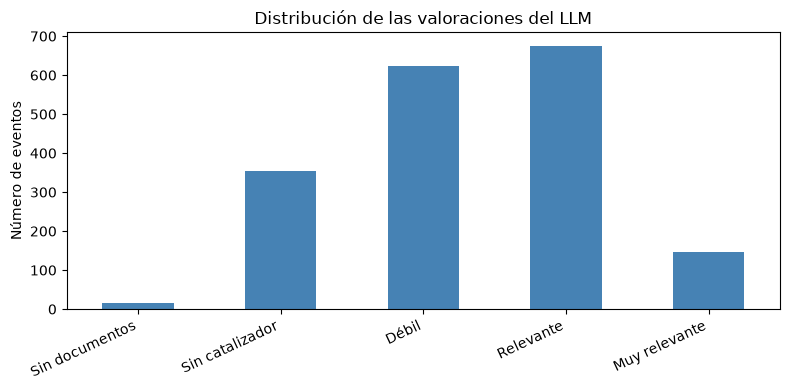

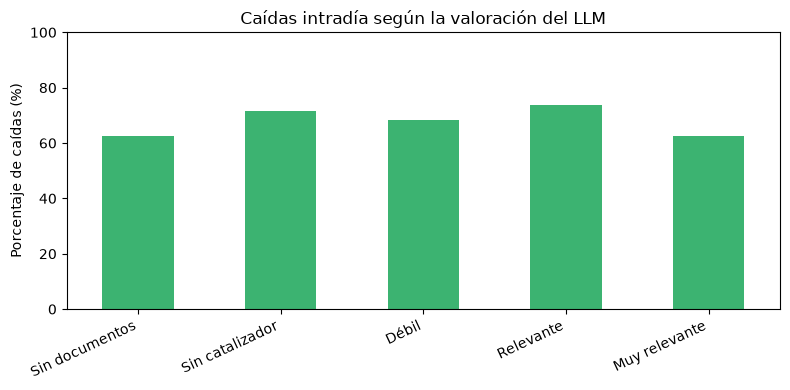

In [22]:
orden = [
    "Sin documentos",
    "Sin catalizador",
    "Débil",
    "Relevante",
    "Muy relevante"
]

# Número de eventos por categoría
tabla_llm.reindex(orden)["Casos"].plot.bar(
    figsize=(8, 4),
    color="steelblue",
    title="Distribución de las valoraciones del LLM"
)

plt.xlabel("")
plt.ylabel("Número de eventos")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


# Porcentaje de caídas según la valoración
tabla_llm.reindex(orden)["Caidas"].plot.bar(
    figsize=(8, 4),
    color="mediumseagreen",
    title="Caídas intradía según la valoración del LLM"
)

plt.xlabel("")
plt.ylabel("Porcentaje de caídas (%)")
plt.ylim(0, 100)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [23]:
# ¿Aporta el LLM señal por sí solo? AUC univariante (0,5 = sin información) de cada variable frente a la caída
from sklearn.metrics import roc_auc_score

senal = []
for variable in ["solidez", "sin_documentos"] + VARIABLES_GAP:
    d = con_contexto[[variable, "crap"]].dropna()
    senal.append({"Variable": variable, "AUC univariante": roc_auc_score(d["crap"], d[variable])})

senal = pd.DataFrame(senal).sort_values("AUC univariante", key=lambda s: (s - 0.5).abs(), ascending=False)
display(senal.round(3))
senal.to_csv(RESULTADOS / "senal_univariante.csv", index=False)


,Variable,AUC univariante
2,gap,0.528
15,gap_previo,0.479
3,log_precio_apertura,0.520
6,rent_5d_previo,0.483
10,pos_cierre_previo,0.484
5,rent_1d_previo,0.488
13,log_volumen_dolares_previo,0.510
14,rotacion_previo,0.508
8,volat_20d_previo,0.493
4,log_cap_previa,0.504


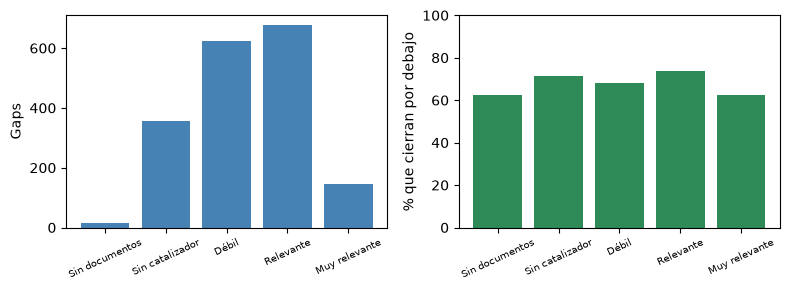

In [24]:
# Figura 5.7: valoración del LLM, número de gaps y porcentaje que cierran por debajo
orden = ["Sin documentos", "Sin catalizador", "Débil", "Relevante", "Muy relevante"]
tl = tabla_llm.reindex(orden)
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].bar(tl.index, tl["Casos"], color="steelblue")
axes[0].set_ylabel("Gaps")
axes[1].bar(tl.index, tl["Caidas"], color="seagreen")
axes[1].set_ylabel("% que cierran por debajo")
axes[1].set_ylim(0, 100)
for ax in axes:
    ax.tick_params(axis="x", labelsize=7, rotation=25)
plt.tight_layout()
plt.savefig(CARPETA_FIG / "figura_5_7.png", dpi=150)
plt.show()

## 8. La comparación principal: ¿añadir el LLM ayuda?

En este apartado comparamos los resultados de los modelos utilizando únicamente variables de mercado y añadiendo las valoraciones del LLM.

Para que la comparación sea justa, utilizamos los mismos eventos, periodos y algoritmos en ambos casos. De esta manera, podemos comprobar si la información extraída de las noticias aporta capacidad predictiva adicional.

La principal métrica de comparación será el AUC, aunque una mejora en esta medida no implica necesariamente que podamos obtener beneficios mediante una estrategia de inversión.

In [25]:
# Preparamos los mismos datos para ambos modelos
variables_comparacion = VARIABLES_GAP + ["solidez", "sin_documentos"]

datos_comparacion = con_contexto.dropna(
    subset=variables_comparacion + ["crap"]
)

# Entrenamos con y sin información del LLM
solo, pred_solo = evaluar_gaps(
    datos_comparacion, VARIABLES_GAP, "Solo mercado"
)

combinado, pred_combinado = evaluar_gaps(
    datos_comparacion, variables_comparacion, "Mercado + LLM"
)

# Comparamos los resultados
comparacion = pd.concat([solo, combinado], ignore_index=True)
display(comparacion.round(3))

# Calculamos la mejora del AUC
tabla_auc = comparacion.pivot(
    index=["Año", "Modelo"],
    columns="Tipo",
    values="AUC"
)

tabla_auc["Mejora AUC"] = (
    tabla_auc["Mercado + LLM"] - tabla_auc["Solo mercado"]
)

display(tabla_auc.round(3))

,Tipo,Año,Modelo,Casos,AUC,F1,Exactitud,Referencia,AUC IC bajo,AUC IC alto
0,Solo mercado,2024,Regresión logística,369,0.563,0.803,0.675,0.672,0.497,0.632
1,Solo mercado,2024,Random Forest,369,0.543,0.804,0.672,0.672,0.476,0.602
2,Solo mercado,2024,Gradient Boosting,369,0.504,0.784,0.667,0.672,0.431,0.560
3,Solo mercado,2025,Regresión logística,517,0.506,0.830,0.710,0.710,0.447,0.562
4,Solo mercado,2025,Random Forest,517,0.555,0.830,0.710,0.710,0.500,0.611
5,Solo mercado,2025,Gradient Boosting,517,0.564,0.798,0.681,0.710,0.509,0.620
6,Solo mercado,2026,Regresión logística,511,0.541,0.821,0.701,0.703,0.486,0.593
7,Solo mercado,2026,Random Forest,511,0.552,0.825,0.703,0.703,0.499,0.607
8,Solo mercado,2026,Gradient Boosting,511,0.535,0.798,0.673,0.703,0.482,0.586
9,Mercado + LLM,2024,Regresión logística,369,0.563,0.803,0.675,0.672,0.507,0.626


Tipo                      Mercado + LLM  Solo mercado  Mejora AUC
Año  Modelo                                                      
2024 Gradient Boosting            0.533         0.504       0.029
     Random Forest                0.562         0.543       0.019
     Regresión logística          0.563         0.563       0.001
2025 Gradient Boosting            0.548         0.564      -0.016
     Random Forest                0.565         0.555       0.010
     Regresión logística          0.509         0.506       0.004
2026 Gradient Boosting            0.522         0.535      -0.013
     Random Forest                0.543         0.552      -0.009
     Regresión logística          0.519         0.541      -0.022

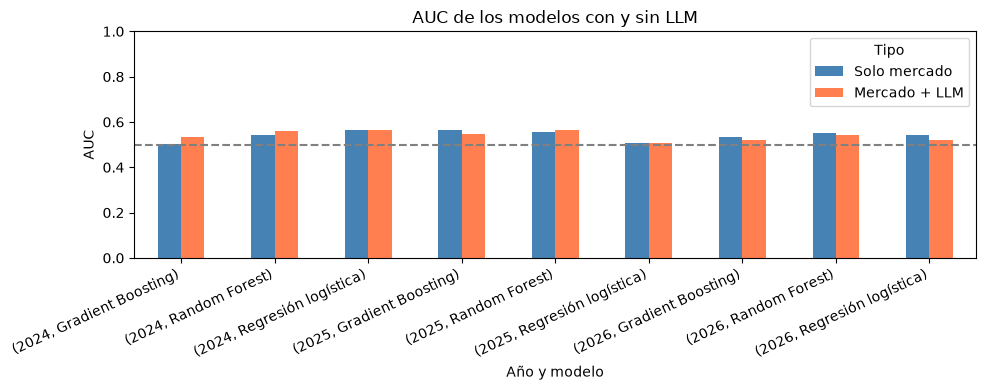

In [26]:
tabla_auc[["Solo mercado", "Mercado + LLM"]].plot.bar(
    figsize=(10, 4),
    color=["steelblue", "coral"],
    title="AUC de los modelos con y sin LLM"
)

plt.axhline(0.5, color="gray", linestyle="--")
plt.xlabel("Año y modelo")
plt.ylabel("AUC")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### ¿La diferencia es clara o puede deberse a la muestra?

Para comprobar cuánto pueden variar las diferencias, repetimos la comparación con muestras de **días completos**, elegidos al azar con reemplazo. Agrupamos por día porque varias acciones de una misma sesión pueden verse afectadas por el mismo mercado.

El intervalo del 95 % no constituye una prueba definitiva. Si incluye cero, **no tenemos evidencia clara de mejora**; si no lo incluye, observamos una diferencia más consistente, aunque siguen existiendo otras limitaciones.

In [27]:
# Unimos las predicciones de ambos modelos
parejas = pred_solo.merge(
    pred_combinado,
    on=["id_evento", "fecha", "Año", "Modelo", "Real"],
    suffixes=("_mercado", "_llm"),
    validate="one_to_one"
)

resultados_bootstrap = []

for (anio, nombre), grupo in parejas.groupby(["Año", "Modelo"]):

    fechas = grupo["fecha"].unique()
    grupos_dias = [
        np.where(grupo["fecha"].to_numpy() == fecha)[0]
        for fecha in fechas
    ]

    y = grupo["Real"].to_numpy()
    p_mercado = grupo["Probabilidad_mercado"].to_numpy()
    p_llm = grupo["Probabilidad_llm"].to_numpy()

    diferencias = []
    rng = np.random.default_rng(42)

    # Repetimos el cálculo 500 veces
    for _ in range(500):
        dias = rng.choice(len(fechas), size=len(fechas), replace=True)
        indices = np.concatenate([grupos_dias[i] for i in dias])

        if len(np.unique(y[indices])) == 2:
            auc_mercado = roc_auc_score(y[indices], p_mercado[indices])
            auc_llm = roc_auc_score(y[indices], p_llm[indices])

            diferencias.append(auc_llm - auc_mercado)

    if diferencias:
        resultados_bootstrap.append({
            "Año": anio,
            "Modelo": nombre,
            "Diferencia AUC": roc_auc_score(y, p_llm) - roc_auc_score(y, p_mercado),
            "Límite inferior": np.percentile(diferencias, 2.5),
            "Límite superior": np.percentile(diferencias, 97.5)
        })

intervalos = pd.DataFrame(resultados_bootstrap)

display(intervalos.round(3))

,Año,Modelo,Diferencia AUC,Límite inferior,Límite superior
0,2024,Gradient Boosting,0.029,0.001,0.055
1,2024,Random Forest,0.019,-0.010,0.050
2,2024,Regresión logística,0.001,-0.030,0.030
3,2025,Gradient Boosting,-0.016,-0.038,0.004
4,2025,Random Forest,0.010,-0.008,0.025
5,2025,Regresión logística,0.004,-0.024,0.027
6,2026,Gradient Boosting,-0.013,-0.036,0.007
7,2026,Random Forest,-0.009,-0.028,0.010
8,2026,Regresión logística,-0.022,-0.048,0.003


### Prueba conjunta 2024–2026

Los resultados por año tienen pocos gaps, así que cada uno detecta solo diferencias grandes. Por eso juntamos las predicciones fuera de muestra de los tres años (1.397 gaps) y repetimos la comparación una sola vez.


In [28]:
# Prueba conjunta: predicciones fuera de muestra de 2024, 2025 y 2026 juntas
parejas_conj = pred_solo.merge(
    pred_combinado,
    on=["id_evento", "fecha", "Año", "Modelo", "Real"],
    suffixes=("_mercado", "_llm")
)

filas_conj = []
for nombre in parejas_conj["Modelo"].unique():
    grupo = parejas_conj[parejas_conj["Modelo"] == nombre]
    y = grupo["Real"].to_numpy()
    p_mercado = grupo["Probabilidad_mercado"].to_numpy()
    p_llm = grupo["Probabilidad_llm"].to_numpy()

    # Remuestreo de días completos (500 repeticiones)
    dias = grupo["fecha"].unique()
    grupos_dias = [np.where(grupo["fecha"].to_numpy() == dia)[0] for dia in dias]
    rng = np.random.default_rng(42)
    diferencias = []
    for _ in range(500):
        elegidos = rng.choice(len(dias), size=len(dias), replace=True)
        indices = np.concatenate([grupos_dias[i] for i in elegidos])
        if len(np.unique(y[indices])) == 2:
            diferencias.append(roc_auc_score(y[indices], p_llm[indices]) - roc_auc_score(y[indices], p_mercado[indices]))

    filas_conj.append({
        "Modelo": nombre,
        "Gaps": len(grupo),
        "AUC solo mercado": roc_auc_score(y, p_mercado),
        "AUC mercado + LLM": roc_auc_score(y, p_llm),
        "Diferencia": roc_auc_score(y, p_llm) - roc_auc_score(y, p_mercado),
        "IC 95 % inferior": np.percentile(diferencias, 2.5),
        "IC 95 % superior": np.percentile(diferencias, 97.5)
    })

conjunta = pd.DataFrame(filas_conj)
display(conjunta.round(3))
conjunta.to_csv(RESULTADOS / "prueba_conjunta_2024_2026.csv", index=False)


,Modelo,Gaps,AUC solo mercado,AUC mercado + LLM,Diferencia,IC 95 % inferior,IC 95 % superior
0,Regresión logística,1397,0.534,0.528,-0.005,-0.021,0.009
1,Random Forest,1397,0.548,0.552,0.004,-0.008,0.015
2,Gradient Boosting,1397,0.535,0.535,0.001,-0.013,0.015


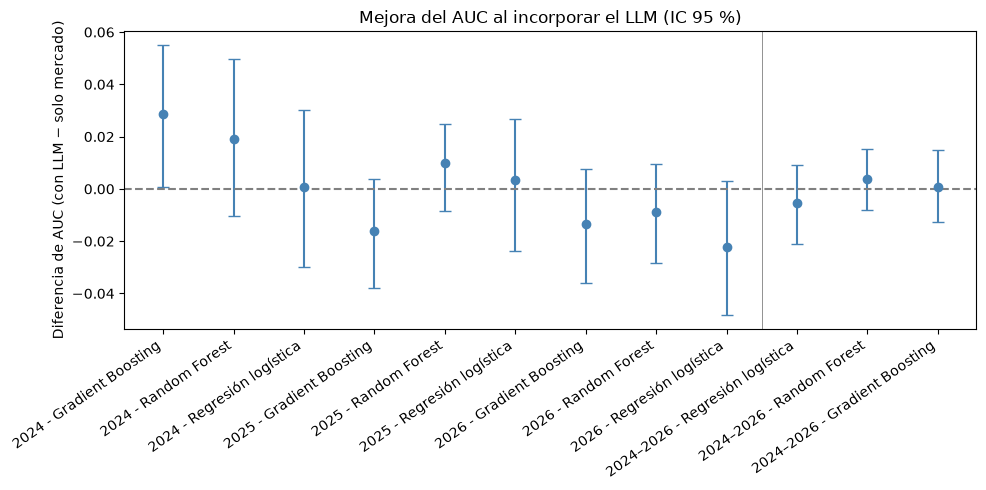

In [29]:
# Figura 5.8: mejora del AUC al incorporar el LLM, por año y en la prueba conjunta (IC 95 %)
conjunta_mejora = conjunta.rename(columns={"Diferencia": "Diferencia AUC", "IC 95 % inferior": "Límite inferior", "IC 95 % superior": "Límite superior"})
mejoras = pd.concat([intervalos, conjunta_mejora], ignore_index=True)
etiquetas = [f"{a} - {m}" for a, m in zip(intervalos["Año"].astype(str), intervalos["Modelo"])]
etiquetas += [f"2024–2026 - {m}" for m in conjunta["Modelo"]]
x = np.arange(len(mejoras))

plt.figure(figsize=(10, 5))
plt.errorbar(
    x,
    mejoras["Diferencia AUC"],
    yerr=[mejoras["Diferencia AUC"] - mejoras["Límite inferior"], mejoras["Límite superior"] - mejoras["Diferencia AUC"]],
    fmt="o", color="steelblue", capsize=4
)
plt.axhline(0, color="gray", linestyle="--")
plt.axvline(len(intervalos) - 0.5, color="gray", linewidth=0.6)
plt.xticks(x, etiquetas, rotation=35, ha="right")
plt.ylabel("Diferencia de AUC (con LLM − solo mercado)")
plt.title("Mejora del AUC al incorporar el LLM (IC 95 %)")
plt.tight_layout()
plt.savefig(CARPETA_FIG / "figura_5_8.png", dpi=150)
plt.show()

In [30]:
# Potencia aproximada: probabilidad de detectar una mejora de AUC con el número de gaps disponible
from scipy.stats import norm

def error_auc(auc, n_pos, n_neg):
    q1 = auc / (2 - auc)
    q2 = 2 * auc * auc / (1 + auc)
    return np.sqrt((auc * (1 - auc) + (n_pos - 1) * (q1 - auc * auc) + (n_neg - 1) * (q2 - auc * auc)) / (n_pos * n_neg))

def potencia(mejora, n, auc_base=0.55, correlacion=0.5):
    n_pos, n_neg = 0.7 * n, 0.3 * n
    e1 = error_auc(auc_base, n_pos, n_neg)
    e2 = error_auc(auc_base + mejora, n_pos, n_neg)
    error_dif = np.sqrt(e1**2 + e2**2 - 2 * correlacion * e1 * e2)
    return norm.cdf(mejora / error_dif - norm.ppf(0.975))

tabla_potencia = pd.DataFrame([
    {"Gaps": n, "Mejora de AUC": m, "Potencia aproximada (%)": 100 * potencia(m, n)}
    for n in [len(eventos[eventos["anio"] == 2025]), len(eventos[eventos["anio"].between(2024, 2026)])]
    for m in [0.02, 0.04, 0.06]
])
display(tabla_potencia.round({"Mejora de AUC": 2, "Potencia aproximada (%)": 0}))
tabla_potencia.to_csv(RESULTADOS / "potencia_gaps.csv", index=False)


,Gaps,Mejora de AUC,Potencia aproximada (%)
0,517,0.02,11.0
1,517,0.04,32.0
2,517,0.06,61.0
3,1397,0.02,23.0
4,1397,0.04,69.0
5,1397,0.06,96.0
